# TikTok Claim Classification

**Portfolio project from the Google Advanced Data Analytics Professional Certificate**

This analysis builds a moderation-triage model that distinguishes videos containing claims from videos expressing opinions. A claim label means the content may merit review; it does **not** mean the content is false.

## Business question

Can video metadata and engagement patterns help a moderation team prioritize videos that make claims? The workflow follows the PACE framework: Plan, Analyze, Construct, and Execute.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATH = ROOT / "data" / "tiktok_dataset.csv"
data = pd.read_csv(DATA_PATH)
print(f"Rows: {len(data):,} | Columns: {data.shape[1]} | Missing rows: {data.isna().any(axis=1).sum():,}")
data.head()

Rows: 19,382 | Columns: 12 | Missing rows: 298


,#,claim_status,video_id,video_duration_sec,video_transcription_text,verified_status,author_ban_status,video_view_count,video_like_count,video_share_count,video_download_count,video_comment_count
0,1,claim,7017666017,59,someone shared with me that drone deliveries a...,not verified,under review,343296.0,19425.0,241.0,1.0,0.0
1,2,claim,4014381136,32,someone shared with me that there are more mic...,not verified,active,140877.0,77355.0,19034.0,1161.0,684.0
2,3,claim,9859838091,31,someone shared with me that american industria...,not verified,active,902185.0,97690.0,2858.0,833.0,329.0
3,4,claim,1866847991,25,someone shared with me that the metro of st. p...,not verified,active,437506.0,239954.0,34812.0,1234.0,584.0
4,5,claim,7105231098,19,someone shared with me that the number of busi...,not verified,active,56167.0,34987.0,4110.0,547.0,152.0


## Analyze

The target is almost balanced, which makes accuracy interpretable but still insufficient on its own. Engagement features are strongly right-skewed, so medians and plots without extreme outliers give a clearer descriptive view.

In [2]:
summary = (data.groupby("claim_status")
           .agg(videos=("video_id", "size"),
                median_views=("video_view_count", "median"),
                median_likes=("video_like_count", "median"),
                median_shares=("video_share_count", "median")))
summary

,videos,median_views,median_likes,median_shares
claim_status,,,,
claim,9608,501555.0,123649.0,17997.5
opinion,9476,4953.0,823.0,121.0


A Welch two-sample t-test in the reproducible pipeline compares mean views for videos from verified and unverified authors. The result shows association, not causation.

## Construct

The modeling workflow uses a stratified 60/20/20 train/validation/test split. Preprocessing is fit only on training data. A majority baseline, logistic regression, random forest, and XGBoost are compared on validation F1; the held-out test set is used once for the selected model.

Run the next cell to regenerate metrics and figures from source.

In [3]:
%run ../src/analysis.py

{
  "data": {
    "raw_rows": 19382,
    "modeling_rows": 19084,
    "claim_share": 0.5034583944665688
  },
  "verification_t_test": {
    "verified_mean_views": 91439.16416666667,
    "not_verified_mean_views": 265663.78533885034,
    "t_statistic": -25.499441780633777,
    "p_value": 2.6088823687177503e-120
  },
  "validation_metrics": {
    "dummy": {
      "accuracy": 0.5035368090123133,
      "precision": 0.5035368090123133,
      "recall": 1.0,
      "f1": 0.669803101585642
    },
    "logistic_regression": {
      "accuracy": 0.978517160073356,
      "precision": 0.999457111834962,
      "recall": 0.9578563995837669,
      "f1": 0.9782146652497343
    },
    "random_forest": {
      "accuracy": 0.9955462405030129,
      "precision": 1.0,
      "recall": 0.9911550468262227,
      "f1": 0.9955578782336033
    },
    "xgboost": {
      "accuracy": 0.994760282944721,
      "precision": 0.9984276729559748,
      "recall": 0.9911550468262227,
      "f1": 0.9947780678851175
    }
  },


In [4]:
metrics = json.loads((ROOT / "reports" / "metrics.json").read_text())
comparison = pd.DataFrame(metrics["validation_metrics"]).T
comparison.round(3)

,accuracy,precision,recall,f1
dummy,0.504,0.504,1.000,0.670
logistic_regression,0.979,0.999,0.958,0.978
random_forest,0.996,1.000,0.991,0.996
xgboost,0.995,0.998,0.991,0.995


## Execute — held-out results

In [5]:
((pd.Series(metrics["test_metrics"], name=metrics["champion_model"]) * 100).round(2).astype(str).add("%").to_frame())

,random_forest
accuracy,99.58%
precision,100.0%
recall,99.17%
f1,99.58%


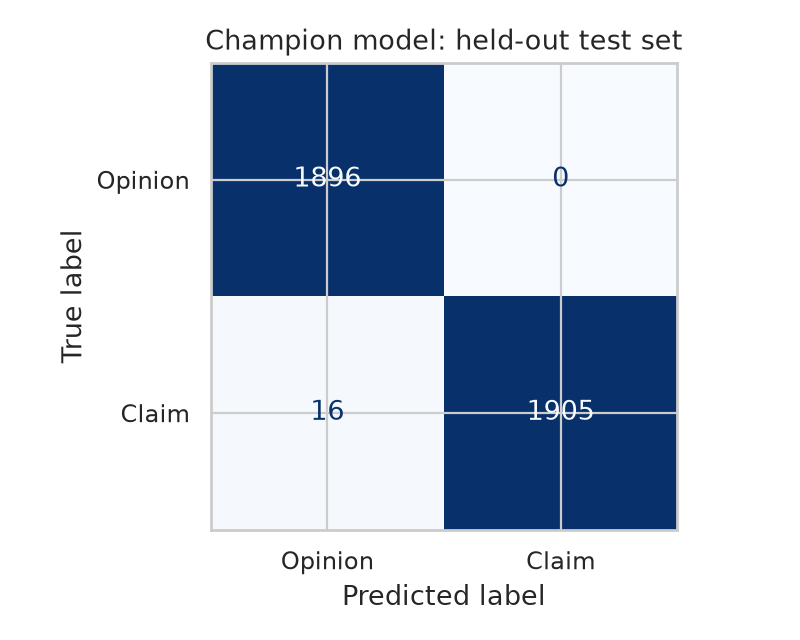

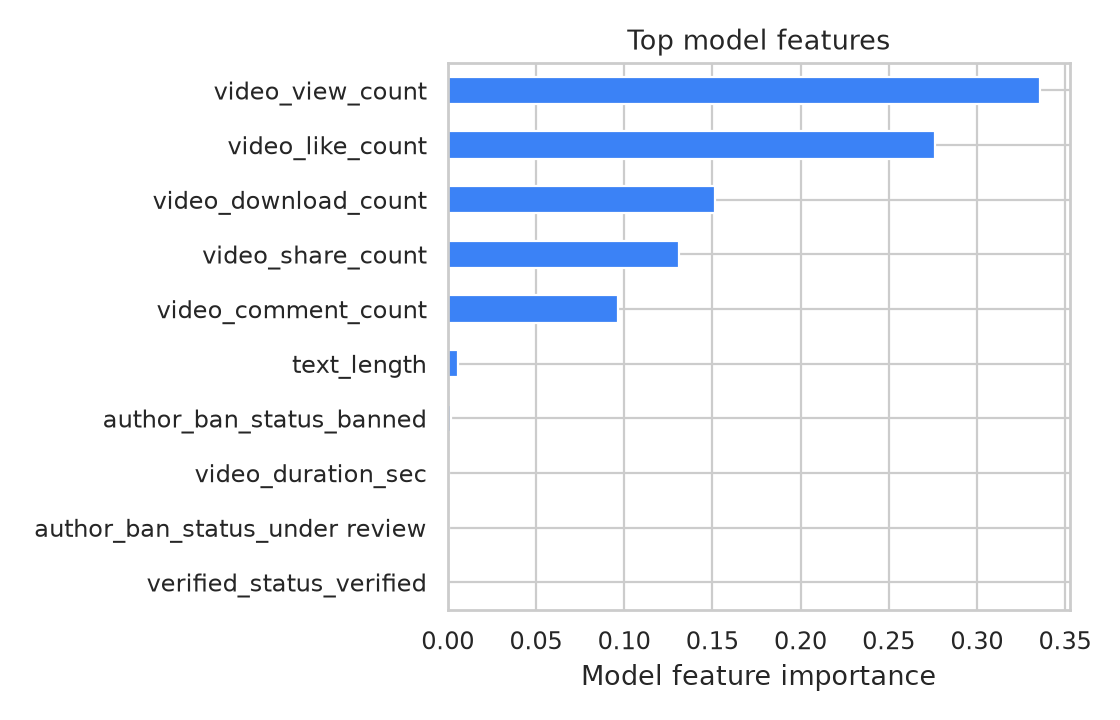

In [6]:
display(Image(filename=str(ROOT / "reports" / "figures" / "confusion_matrix.png"), width=520))
display(Image(filename=str(ROOT / "reports" / "figures" / "feature_importance.png"), width=650))

## Recommendation and limitations

The model is suitable as a **review-prioritization aid** in this educational dataset. Before any real deployment, it needs evaluation on current, independently collected TikTok data, subgroup fairness checks, probability calibration, drift monitoring, and a threshold selected with the moderation team. Engagement signals are generated after publication, so this feature set cannot support classification at upload time. The label identifies claims, not misinformation.